# MedEHA 实体–Patch 注意力可视化

MedEHA 在 `entity_extraction=True` 时，**PFA/ICA/LGA 的对齐单位是三元组实体 token**（`merge_entity` 将 observation / anatomy / state 融合后的局部表示），而不是 BERT 报告里的单个词。

**推荐可视化对象（主）**：每个 `(obs, ana, sta)` 实体对应 1 个 entity token → patch 的 cross-attention / grouping 权重。

**可选（辅）**：`entity_align + with_report_feat` 时，可额外看 report word → patch（与训练里 PFA-RI 分支一致）。

使用前请修改 `CKPT_PATH`，并在下方按 `(batch_idx, entity_token_idx)` 或 `(obs_name, ana_name)` 指定要画的实体。

In [151]:
import os
import json
import numpy as np
import cv2
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from einops import rearrange

from medeha.datasets.transforms import DataTransforms
from medeha.datasets.data_module import DataModule
from medeha.datasets.pretrain_dataset import (
    MultimodalPretrainingDataset,
    multimodal_collate_fn,
)
from medeha.pretrain.module import MedEHA

os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [152]:
# ===== 用户配置 =====
# CKPT_PATH = "/mnt/C/kxm/medeha_ckpts/medeha2/abl_entity_ep0_wrepfeat_erdecl4_0.5esp_0.5ptp_lgro0.2/2026_04_17_19_34_45/epoch=16-step=25992.ckpt"
# CKPT_PATH = "/mnt/C/kxm/medeha_ckpts/medeha2/abl_entity_ep0_wrepfeat_erdecl4_1esp_1ptp_lgro0.2/2026_04_22_08_22_39/epoch=20-step=32108.ckpt"
# CKPT_PATH = "/mnt/C/kxm/medeha_ckpts/medeha2/abl_entity_ep0_wrepfeat_erdecl4_esp_ptp_lgro0.2/2026_04_08_23_23_04/epoch=16-step=25992.ckpt"
CKPT_PATH = "/mnt/C/kxm/medeha_ckpts/medeha2/abl_entity_ep0_wsenfeat_erdecl4_1esp_1ptp_lgro0.2/2026_05_13_19_38_15/epoch=21-step=33659.ckpt"
BATCH_SIZE = 72
DATA_PCT = 1.0

model = MedEHA.load_from_checkpoint(CKPT_PATH, strict=False)
model.eval().to(device)

if not getattr(model.hparams, "entity_extraction", False):
    raise ValueError("该 notebook 面向 entity_extraction 模型，请换用 entity 预训练 ckpt。")

datamodule = DataModule(
    MultimodalPretrainingDataset,
    multimodal_collate_fn,
    DataTransforms,
    DATA_PCT,
    BATCH_SIZE,
    1,
    entity_extraction=True,
    sentence_token=bool(getattr(model.hparams, "sentence_token", False)),
    max_report_sents=int(getattr(model.hparams, "max_report_sents", 30)),
    max_words_sent=int(getattr(model.hparams, "max_words_sent", 30)),
)

for batch in datamodule.val_dataloader():
    batch = {k: v.to(device) if torch.is_tensor(v) else v for k, v in batch.items()}
    break

Preprocessing entities explanations...


In [153]:
def _mean_attn_weights(attn):
    if attn.dim() == 4:
        attn = attn.mean(dim=1)
    return attn


with torch.no_grad():
    obs_ids = batch["entity_ids"][0]
    ana_ids = batch["entity_ids"][1]

    all_ids = torch.unique(torch.cat([obs_ids, ana_ids + obs_ids.max() + 1]))
    obs_mask = all_ids <= obs_ids.max()
    ana_mask = ~obs_mask

    _device = obs_ids.device
    model.obs_tokens = model.obs_tokens.to(_device)
    model.ana_tokens = model.ana_tokens.to(_device)
    max_len = max(
        model.obs_tokens["input_ids"].size(1),
        model.ana_tokens["input_ids"].size(1),
    )

    all_input_ids = torch.zeros(len(all_ids), max_len, dtype=torch.long, device=_device)
    all_attention_mask = torch.zeros(len(all_ids), max_len, dtype=torch.long, device=_device)
    all_token_type_ids = torch.zeros(len(all_ids), max_len, dtype=torch.long, device=_device)

    obs_count = obs_mask.sum().item()
    if obs_count > 0:
        obs_indices = all_ids[obs_mask]
        obs_input = model.obs_tokens["input_ids"][obs_indices]
        obs_attn = model.obs_tokens["attention_mask"][obs_indices]
        all_input_ids[:obs_count, : obs_input.size(1)] = obs_input
        all_attention_mask[:obs_count, : obs_attn.size(1)] = obs_attn

    ana_count = ana_mask.sum().item()
    if ana_count > 0:
        ana_indices = all_ids[ana_mask] - obs_ids.max() - 1
        ana_input = model.ana_tokens["input_ids"][ana_indices]
        ana_attn = model.ana_tokens["attention_mask"][ana_indices]
        all_input_ids[obs_count : obs_count + ana_count, : ana_input.size(1)] = ana_input
        all_attention_mask[obs_count : obs_count + ana_count, : ana_attn.size(1)] = ana_attn

    all_feat_q, _, _, _ = model.text_encoder_q(
        all_input_ids, all_attention_mask, all_token_type_ids
    )
    obs_feat_q = all_feat_q[:obs_count]
    ana_feat_q = all_feat_q[obs_count:]
    _, obs_book_loc = torch.unique(obs_ids, return_inverse=True)
    _, ana_book_loc = torch.unique(ana_ids, return_inverse=True)
    obs_feat_q = obs_feat_q[obs_book_loc]
    ana_feat_q = ana_feat_q[ana_book_loc]
    sta_feat_q = model.status_embedding(batch["entity_ids"][2].long())

    report_enc_for_merge = None
    rep_memory_mask = None
    if model.hparams.with_report_feat:
        if (
            model.hparams.with_token_feat
            and model.hparams.sentence_token
            and batch.get("caption_is_sentence", False)
        ):
            rs, _, _, _ = model.text_encoder_q(
                batch["caption_ids"], batch["attention_mask"], batch["token_type_ids"]
            )
            bz = batch["imgs"].size(0)
            report_enc_for_merge, rep_memory_mask = model._scatter_sentence_report_feats(
                rs, batch["reportindex"], bz, model.hparams.max_report_sents
            )
        elif model.hparams.with_token_feat:
            _, word_f, _, _ = model.text_encoder_q(
                batch["caption_ids"], batch["attention_mask"], batch["token_type_ids"]
            )
            report_enc_for_merge = word_f
            rep_memory_mask = model._word_memory_padding_mask(
                batch["attention_mask"], word_f.size(1)
            )
        else:
            report_enc_for_merge, _, _, _ = model.text_encoder_q(
                batch["caption_ids"], batch["attention_mask"], batch["token_type_ids"]
            )

    report_feat_q, token_feat_q, token_attn_q, _ = model.merge_entity(
        obs_feat_q,
        ana_feat_q,
        sta_feat_q,
        batch["entindex"],
        batch["entity_ids"].t(),
        rep_feat=report_enc_for_merge,
        rep_memory_mask=rep_memory_mask,
    )

    if model._use_entity_align():
        token_emb_q = model._entity_local_project(token_feat_q)
    else:
        token_emb_q = model.text_encoder_q.local_embed(token_feat_q)

    _, patch_feat_q, _ = model.img_encoder_q(batch["imgs"], None)
    patch_emb_q = model.img_encoder_q.local_embed(patch_feat_q)
    token_emb_q = F.normalize(token_emb_q, dim=-1)
    patch_emb_q = F.normalize(patch_emb_q, dim=-1)

    # 与 visualize_attention_map_bp 一致：token_local_atten（entity token -> patch）
    _, word_atten = model.token_local_atten_layer(
        token_emb_q, patch_emb_q, patch_emb_q, need_weights=True
    )
    word_atten = _mean_attn_weights(word_atten)

    bz = batch["imgs"].size(0)
    num_patches = patch_feat_q.size(1)
    p1 = p2 = int(num_patches ** 0.5)

print(f"word_atten shape={tuple(word_atten.shape)}, patches={num_patches} ({p1}x{p2})")
print(
    f"language_group={model.hparams.language_group}, "
    f"entity_align={model.hparams.entity_align}"
)

word_atten shape=(72, 30, 196), patches=196 (14x14)
language_group=True, entity_align=False


In [154]:
# 每张图的实体列表：(obs, ana, sta) 三元组，顺序与 merge_entity 的 token 行一致
obs_names = list(model.obs_book.keys())
ana_names = list(model.ana_book.keys())
batch_obs = np.array(obs_names)[np.array(obs_ids.cpu())]
batch_ana = np.array(ana_names)[np.array(ana_ids.cpu())]
batch_sta = np.array(batch["entity_ids"][2].cpu().tolist())

batch_triplets = [
    (str(o), str(a), int(s)) for o, a, s in zip(batch_obs, batch_ana, batch_sta)
]

sents = [[] for _ in range(bz)]
for n_b in range(bz):
    mask = batch["entindex"].cpu() == n_b
    sents[n_b] = [batch_triplets[i] for i in np.where(mask.numpy())[0]]

print(f"batch 内样本数={bz}, 示例实体数={[len(s) for s in sents[:5]]}")
STA_LABELS = {0: "absent", 1: "present"}


def format_triplet(t):
    """显示完整 (obs, ana, sta) 三元组。"""
    sta = STA_LABELS.get(int(t[2]), str(t[2]))
    return f"{t[0]}, {t[1]}, {sta}"


if sents and sents[0]:
    print("示例三元组:", format_triplet(sents[0][0]))

batch 内样本数=72, 示例实体数=[6, 7, 7, 5, 11]
示例三元组: effusion, left_pleural, present


In [160]:
# 在 batch 中搜索含关键词的实体
keyword = "edema"  # 可改为 edema / atelectasis / cardiomegaly / pneumothorax 等

for ind in range(len(sents)):
    for i, triplet in enumerate(sents[ind]):
        if keyword in triplet[0] or keyword in triplet[1]:
            print(format_triplet(triplet), f"-> [{ind}, {i}]")

edema, pulmonary, absent -> [1, 3]
edema, pulmonary, present -> [2, 4]
edema, pulmonary, present -> [4, 5]
edema, pulmonary, absent -> [7, 8]
edema, pulmonary, absent -> [8, 5]
edema, interstitium, present -> [14, 3]
edema, pulmonary, absent -> [19, 3]
edema, interstitium, present -> [20, 0]
edema, pulmonary, absent -> [23, 5]
edema, pulmonary, absent -> [25, 5]
edema, pulmonary, absent -> [27, 2]
edema, pulmonary, absent -> [30, 4]
edema, pulmonary, absent -> [32, 2]
edema, unspecified, absent -> [33, 8]
edema, pulmonary, absent -> [34, 3]
edema, pulmonary, absent -> [37, 3]
edema, pulmonary, absent -> [38, 8]
edema, interstitium, present -> [42, 5]
edema, lung_volumes, present -> [42, 6]
edema, unspecified, present -> [42, 7]
edema, pulmonary, present -> [43, 6]
edema, pulmonary, absent -> [45, 4]
edema, pulmonary, present -> [58, 6]
edema, pulmonary, present -> [59, 6]
edema, pulmonary, present -> [65, 5]
edema, pulmonary, present -> [68, 3]
edema, pulmonary, present -> [70, 3]
edem

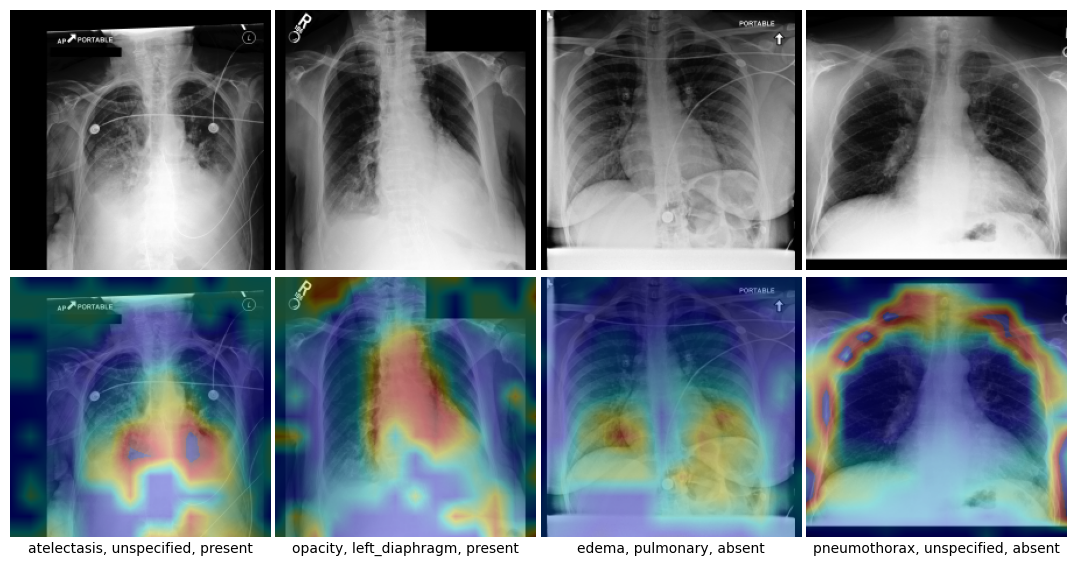

In [169]:
indices = [
    [4, 7],   # atelectasis
    [37,1],   # opacity
    [32, 2],   # edema
    [25, 6],   # pneumothorax
]

fig, axes = plt.subplots(2, len(indices))
fig.set_figheight(6)
fig.set_figwidth(11)

for i, (img_idx, word_idx) in enumerate(indices):
    img = (batch["imgs"].cpu().numpy() * 0.5 + 0.5).clip(0, 1)[img_idx].transpose(1, 2, 0)
    img = (img * 255).astype(np.uint8)
    axes[0, i].axis("off")
    axes[1, i].axis("off")

    row_atten = word_atten[img_idx].clone()
    row_atten = row_atten / row_atten.max().clamp(min=1e-8)
    atten_map = rearrange((1 - row_atten) * 2, "b (p1 p2) -> b p1 p2", p1=p1, p2=p2)
    atten_map = F.interpolate(
        atten_map.unsqueeze(1).float(),
        size=[224, 224],
        mode="bilinear",
        align_corners=True,
    ).squeeze()
    atten_map = (atten_map.detach().cpu().numpy() * 255).astype(np.uint8)
    heatmap = cv2.applyColorMap(atten_map[word_idx, ..., None], cv2.COLORMAP_JET)

    axes[0, i].imshow(img)
    axes[1, i].imshow((heatmap * 0.3 + img * 0.6).astype(np.uint8))

    label = format_triplet(sents[img_idx][word_idx])
    axes[1, i].text(
        112, 228, label, fontsize=10, ha="center", va="top",
    )

plt.subplots_adjust(left=0.02, right=0.98, top=0.98, bottom=0.1, wspace=0.02, hspace=0.02)
plt.show()